# 04 — Random Forest Churn Model (M4)
**Project:** Customer Churn Analytics & Prediction (Telco dataset)  
**Owner:** Muskan  **Output files:** `04_random_forest.ipynb` + `random_forest.pkl`

**Goal:** train a Random Forest classifier on exactly the same data, features, train/test split and preprocessing as the Logistic Regression baseline (M3) and XGBoost (M5), run a reasonable and limited parameter search, evaluate with Accuracy, Precision, Recall, F1 and ROC-AUC, and extract feature importance so M6 and M7 can use the results.

**Execution order:** run the cells top to bottom (Kernel → Restart & Run All). Runtime is about a minute or two on a normal laptop; no GPU is needed.

**Fairness rules kept from M3 / M5:**
- same file: `telco_with_ids.csv` (M2 output)
- same target: `ChurnFlag` (1 = churned)
- same dropped columns: `customerID`, `Churn`, `tenure_group`, `charges_group`, `ChurnFlag`
- same split: `test_size=0.20`, `random_state=42`, `stratify=y`
- same preprocessing pipeline (imputer + one-hot encoding)
- tuning uses cross-validation on the **training set only**; the test set is touched once, for final evaluation

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42          # one seed everywhere, documented for reproducibility
sns.set_theme(style="whitegrid")
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.8.0


## 1. Load the data (same file as the Logistic Regression and XGBoost notebooks)

In [2]:
# Looks for the M2 output next to this notebook, in the project folders, or in Drive-style folders.
CANDIDATES = [
    "telco_with_ids.csv",
    "../02_M2_EDA/telco_with_ids.csv",
    "02_M2_EDA/telco_with_ids.csv",
    "../data/processed/telco_with_ids.csv",
    "data/processed/telco_with_ids.csv",
]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("telco_with_ids.csv not found. Put it next to this notebook or edit CANDIDATES.")

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH, "| shape:", df.shape)
print("\nMissing values:", int(df.isnull().sum().sum()))
print("\nChurn distribution:")
print(df["Churn"].value_counts())
print((df["Churn"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

Loaded: telco_with_ids.csv | shape: (7043, 24)

Missing values: 0

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46 %
Yes    26.54 %
Name: proportion, dtype: str


## 2. Features, target and the shared train/test split

In [3]:
drop_columns = ["customerID", "Churn", "tenure_group", "charges_group", "ChurnFlag"]
X = df.drop(columns=drop_columns)
y = df["ChurnFlag"].astype(int)
ids = df["customerID"]

# numeric = numbers; categorical = everything else (same split of columns as M3 / M5)
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]
print("Numeric features    :", numeric_features)
print("Categorical features:", len(categorical_features), "columns")

# identical to M3 / M5: 80/20, stratified, random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("\nTrain:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate  train: %.4f  test: %.4f" % (y_train.mean(), y_test.mean()))

Numeric features    : ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: 16 columns

Train: (5634, 19) | Test: (1409, 19)
Churn rate  train: 0.2654  test: 0.2654


## 3. Preprocessing + class imbalance
Same `ColumnTransformer` as M3 / M5 (median imputer + scaler for numbers, most-frequent imputer + one-hot for categories). Scaling is not needed by tree models but is harmless and keeps the pipeline identical across all three models.

Only ~26.5% of customers churn. M3 used `class_weight="balanced"`; Random Forest uses the same idea with `class_weight="balanced_subsample"` (weights are recomputed inside each tree's bootstrap sample).

In [4]:
numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median")),
                                ("scaler", StandardScaler())])
categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                    ("encoder", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_transformer, numeric_features),
                                  ("cat", categorical_transformer, categorical_features)])

def make_pipeline(**params):
    clf = RandomForestClassifier(class_weight="balanced_subsample",
                                 random_state=RANDOM_STATE, n_jobs=1, **params)
    return Pipeline([("preprocessor", preprocessor), ("classifier", clf)])

def evaluate(model, X_eval, y_eval, threshold=0.5):
    prob = model.predict_proba(X_eval)[:, 1]
    pred = (prob >= threshold).astype(int)
    return {
        "Accuracy":  accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall":    recall_score(y_eval, pred, zero_division=0),
        "F1-score":  f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_eval, prob),
    }, pred, prob

## 4. Baseline Random Forest (untuned, near-default settings)

In [5]:
baseline = make_pipeline(n_estimators=300)
baseline.fit(X_train, y_train)
base_metrics, _, _ = evaluate(baseline, X_test, y_test)
print("Baseline Random Forest (untuned) on the test set:")
print(pd.Series(base_metrics).round(4).to_string())

Baseline Random Forest (untuned) on the test set:
Accuracy     0.7828
Precision    0.6156
Recall       0.4840
F1-score     0.5419
ROC-AUC      0.8217


## 5. Limited parameter search (training data only)
A fully grown forest over-fits a small dataset (~5.6k training rows), so the search focuses on the parameters that control tree complexity. 20 random combinations out of the grid below are scored with 5-fold stratified cross-validation on the **training set** using **ROC-AUC** (threshold-independent, a sound basis for ranking churn risk).

| Parameter | Values | Why |
|---|---|---|
| `n_estimators` | 200, 300, 500 | number of trees |
| `max_depth` | 4, 6, 8, 12 | limits tree depth (over-fitting control) |
| `min_samples_leaf` | 1, 5, 10, 20 | minimum customers per leaf |
| `max_features` | `sqrt`, `log2`, 0.3 | features tried per split |

In [6]:
param_dist = {
    "classifier__n_estimators": [200, 300, 500],
    "classifier__max_depth": [4, 6, 8, 12],
    "classifier__min_samples_leaf": [1, 5, 10, 20],
    "classifier__max_features": ["sqrt", "log2", 0.3],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(make_pipeline(), param_dist, n_iter=20, scoring="roc_auc",
                            cv=cv, n_jobs=-1, refit=True, random_state=RANDOM_STATE)
search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(search.best_score_, 4))
print("Best parameters:")
for k, v in search.best_params_.items():
    print(f"  {k.replace('classifier__', ''):<18} {v}")

cv_table = (pd.DataFrame(search.cv_results_)
            .loc[:, ["param_classifier__n_estimators", "param_classifier__max_depth",
                     "param_classifier__min_samples_leaf", "param_classifier__max_features",
                     "mean_test_score", "std_test_score"]]
            .rename(columns=lambda c: c.replace("param_classifier__", ""))
            .sort_values("mean_test_score", ascending=False).head(5).round(4))
cv_table

Best CV ROC-AUC: 0.8482
Best parameters:
  n_estimators       300
  min_samples_leaf   5
  max_features       0.3
  max_depth          6


,n_estimators,max_depth,min_samples_leaf,max_features,mean_test_score,std_test_score
15,300,6,5,0.3,0.8482,0.0097
8,200,6,10,0.3,0.8482,0.0100
7,500,6,5,0.3,0.8481,0.0099
17,200,6,20,0.3,0.8479,0.0098
11,200,8,10,sqrt,0.8478,0.0093


## 6. Final evaluation on the held-out test set

In [7]:
best_model = search.best_estimator_
metrics, y_pred, y_prob = evaluate(best_model, X_test, y_test)

print("TUNED Random Forest — test-set results (threshold 0.5)")
for k, v in metrics.items():
    print(f"  {k:<10}: {v:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"], zero_division=0))

comparison = pd.DataFrame({"Baseline Random Forest": base_metrics, "Tuned Random Forest": metrics}).round(4)
comparison

TUNED Random Forest — test-set results (threshold 0.5)
  Accuracy  : 0.7537
  Precision : 0.5242
  Recall    : 0.7834
  F1-score  : 0.6281
  ROC-AUC   : 0.8442

Classification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.74      0.82      1035
       Churn       0.52      0.78      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



,Baseline Random Forest,Tuned Random Forest
Accuracy,0.7828,0.7537
Precision,0.6156,0.5242
Recall,0.4840,0.7834
F1-score,0.5419,0.6281
ROC-AUC,0.8217,0.8442


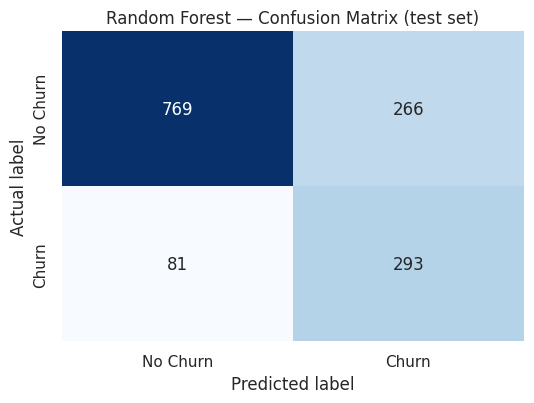

True negatives 769 | False positives 266 | False negatives 81 | True positives 293
The model catches 293 of 374 churners (78.3%); 266 loyal customers are flagged by mistake.


In [8]:
os.makedirs("figures", exist_ok=True)
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
ax.set_xlabel("Predicted label"); ax.set_ylabel("Actual label")
ax.set_title("Random Forest — Confusion Matrix (test set)")
plt.tight_layout(); plt.savefig("figures/random_forest_confusion_matrix.png", dpi=150); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"True negatives {tn} | False positives {fp} | False negatives {fn} | True positives {tp}")
print(f"The model catches {tp} of {tp+fn} churners ({tp/(tp+fn):.1%}); {fp} loyal customers are flagged by mistake.")

## 7. ROC curve — with the Logistic Regression baseline on the same test set
The saved M3 `.pkl` can fail to open on a different scikit-learn version, so the baseline is **re-fitted here with M3's exact settings** (`class_weight="balanced"`, `max_iter=2000`, `random_state=42`, same split and preprocessing). It is used only for this like-for-like comparison.

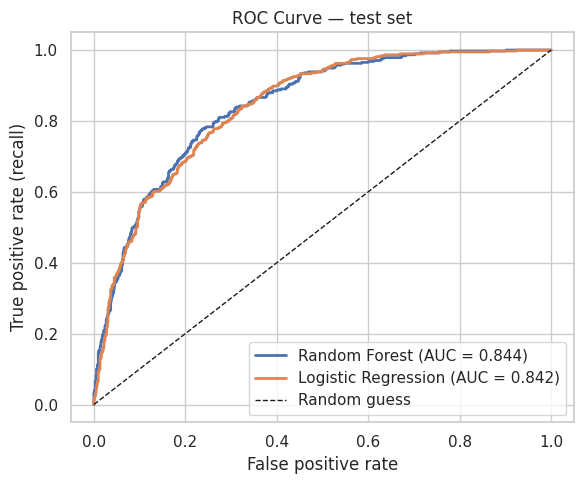

,Logistic Regression (M3 settings),Random Forest (M4)
Accuracy,0.7381,0.7537
Precision,0.5043,0.5242
Recall,0.7834,0.7834
F1-score,0.6136,0.6281
ROC-AUC,0.8415,0.8442


In [9]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

lr = Pipeline([("preprocessor", clone(preprocessor)),
               ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced",
                                                 random_state=RANDOM_STATE))])
lr.fit(X_train, y_train)
lr_metrics, _, lr_prob = evaluate(lr, X_test, y_test)

fpr, tpr, _ = roc_curve(y_test, y_prob)
f2, t2, _ = roc_curve(y_test, lr_prob)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, lw=2, label=f"Random Forest (AUC = {metrics['ROC-AUC']:.3f})")
ax.plot(f2, t2, lw=2, label=f"Logistic Regression (AUC = {lr_metrics['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC Curve — test set"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figures/random_forest_roc_curve.png", dpi=150); plt.show()

pd.DataFrame({"Logistic Regression (M3 settings)": lr_metrics, "Random Forest (M4)": metrics}).round(4)

## 8. Feature importance (what drives churn predictions)
Importance is the Random Forest's impurity-based importance (share of total impurity reduction). One-hot columns are shown individually (e.g. `Contract_Month-to-month`), and also **rolled up to the original customer column** (e.g. all `Contract_*` columns → `Contract`), which is easier to explain and use in Power BI.

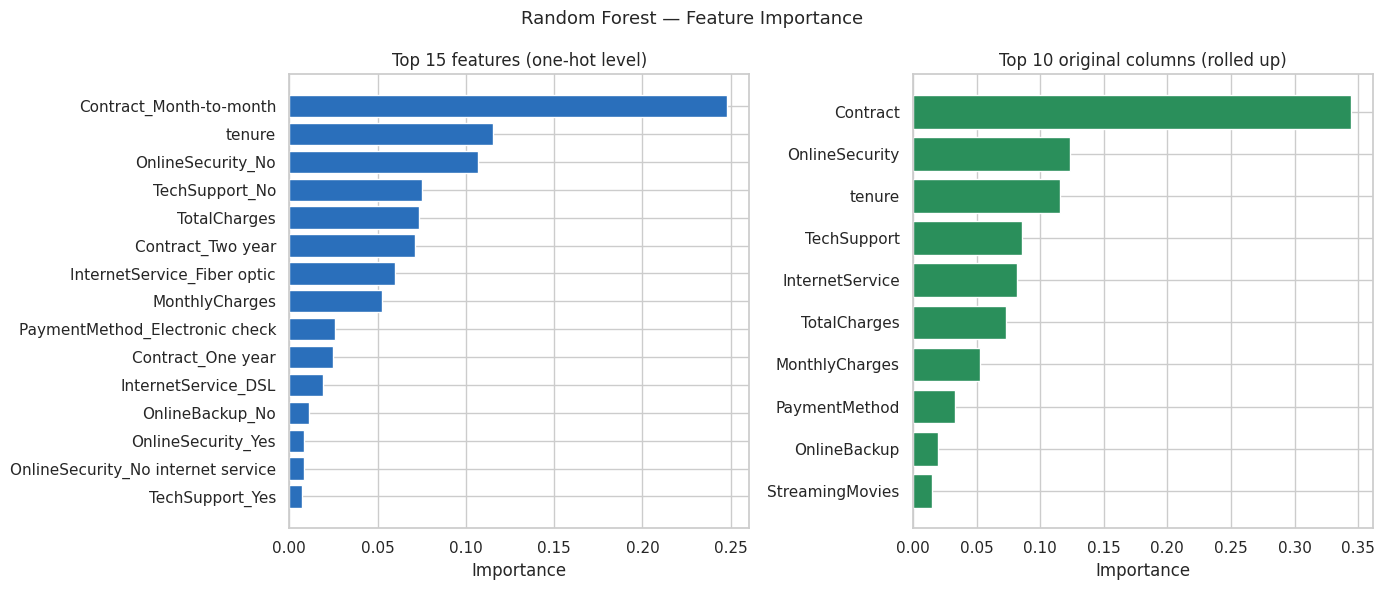

,original_column,importance
0,Contract,0.3445
1,OnlineSecurity,0.1236
2,tenure,0.1156
3,TechSupport,0.0859
4,InternetService,0.0819
5,TotalCharges,0.0733
6,MonthlyCharges,0.0525
7,PaymentMethod,0.0331
8,OnlineBackup,0.0198
9,StreamingMovies,0.0151


In [10]:
pre = best_model.named_steps["preprocessor"]
clf = best_model.named_steps["classifier"]
names = [n.replace("num__", "").replace("cat__", "") for n in pre.get_feature_names_out()]

importance = (pd.DataFrame({"feature": names, "importance": clf.feature_importances_})
              .sort_values("importance", ascending=False).reset_index(drop=True))

def parent_column(feature):
    # one-hot names look like "<Column>_<Category>"; match against the original column names
    for col in sorted(X.columns, key=len, reverse=True):
        if feature == col or feature.startswith(col + "_"):
            return col
    return feature
importance["original_column"] = importance["feature"].map(parent_column)
importance_grouped = (importance.groupby("original_column", as_index=False)["importance"].sum()
                      .sort_values("importance", ascending=False).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
top = importance.head(15).iloc[::-1]
axes[0].barh(top["feature"], top["importance"], color="#2a6fbb")
axes[0].set_xlabel("Importance"); axes[0].set_title("Top 15 features (one-hot level)")
topg = importance_grouped.head(10).iloc[::-1]
axes[1].barh(topg["original_column"], topg["importance"], color="#2a8f5b")
axes[1].set_xlabel("Importance"); axes[1].set_title("Top 10 original columns (rolled up)")
fig.suptitle("Random Forest — Feature Importance", fontsize=13)
plt.tight_layout(); plt.savefig("figures/random_forest_feature_importance.png", dpi=150); plt.show()
importance_grouped.head(10).round(4)

## 9. Save the model, metrics and test-set predictions

In [11]:
# Whole pipeline (preprocessing + tuned Random Forest) so it can predict from raw customer columns.
joblib.dump(best_model, "random_forest.pkl", compress=3)
print("Saved model: random_forest.pkl (%.1f MB)" % (os.path.getsize("random_forest.pkl") / 1e6))

results = {
    "model": "Random Forest",
    "test_size": 0.20, "random_state": RANDOM_STATE, "threshold": 0.5,
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "sklearn_version": sklearn.__version__,
    "best_params": {k.replace("classifier__", ""): (v.item() if hasattr(v, "item") else v)
                    for k, v in search.best_params_.items()},
    "class_weight": "balanced_subsample",
    "cv_roc_auc": round(float(search.best_score_), 4),
    "baseline_untuned_metrics": {k: round(float(v), 4) for k, v in base_metrics.items()},
    "test_metrics": {k: round(float(v), 4) for k, v in metrics.items()},
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
}
with open("random_forest_metrics.json", "w") as f:
    json.dump(results, f, indent=2)
pd.DataFrame([{"Model": "Random Forest", **results["test_metrics"]}]).to_csv("random_forest_metrics.csv", index=False)
importance.round(6).to_csv("random_forest_feature_importance.csv", index=False)
importance_grouped.round(6).to_csv("random_forest_feature_importance_grouped.csv", index=False)

# same rows/order as the shared test set -> M6 can join on customerID
pd.DataFrame({"customerID": ids.loc[X_test.index].values,
              "actual_churn": y_test.values,
              "rf_predicted_churn": y_pred,
              "rf_churn_probability": y_prob.round(6)}).to_csv("random_forest_test_predictions.csv", index=False)
print("Saved: random_forest_metrics.json / .csv, random_forest_feature_importance(.csv/_grouped.csv), random_forest_test_predictions.csv, figures/*.png")

Saved model: random_forest.pkl (1.3 MB)
Saved: random_forest_metrics.json / .csv, random_forest_feature_importance(.csv/_grouped.csv), random_forest_test_predictions.csv, figures/*.png


## 10. Reload check — predict one customer from the saved file

In [12]:
loaded = joblib.load("random_forest.pkl")
check = loaded.predict_proba(X_test)[:, 1]
print("Reloaded model reproduces test probabilities exactly:", np.allclose(check, y_prob))

sample = X_test.iloc[[0]]
p = loaded.predict_proba(sample)[0, 1]
print("\nSample customer ->", "Churn" if p >= 0.5 else "No Churn", f"| churn probability {p:.2%}")
print("Actual label    ->", "Churn" if y_test.iloc[0] == 1 else "No Churn")

Reloaded model reproduces test probabilities exactly: True



Sample customer -> No Churn | churn probability 4.80%
Actual label    -> No Churn


## 11. Summary for the team (M6 and M7)
**Final model:** Random Forest, tuned with 5-fold CV on the training set (20 random combinations, scored by ROC-AUC)  
**Parameters:** `n_estimators=300`, `max_depth=6`, `min_samples_leaf=5`, `max_features=0.3`, `class_weight="balanced_subsample"`, `random_state=42`

| Metric (test set, 1,409 customers, threshold 0.5) | Random Forest | XGBoost (M5) | Logistic Regression (M3) |
|---|---|---|---|
| Accuracy | 0.7537 | 0.7424 | 0.7381 |
| Precision (churn) | 0.5242 | 0.5094 | 0.5043 |
| Recall (churn) | 0.7834 | 0.7995 | 0.7834 |
| F1-score (churn) | 0.6281 | 0.6223 | 0.6136 |
| ROC-AUC | 0.8442 | 0.8443 | 0.8415 |

Confusion matrix: TN 769, FP 266, FN 81, TP 293 — the model finds about 78% of the customers who actually churned; 266 loyal customers are flagged by mistake.

**Findings**
- Tuning mattered. The untuned forest (fully grown trees) reached ROC-AUC 0.822 and churn recall of only 0.484; the tuned, shallower forest reaches ROC-AUC 0.844 and recall 0.783. Limiting depth and leaf size was the key to reducing over-fitting. Accuracy fell (0.783 → 0.754) because the model now flags more churners, which is the right trade-off for churn prediction.
- All three models are very close. Random Forest and XGBoost are tied on ROC-AUC (0.8442 vs 0.8443), and both are only ~0.003 above Logistic Regression. Random Forest has the best accuracy, precision and F1 of the three; XGBoost has the best recall. M6 should decide on churn recall / F1 / ROC-AUC rather than accuracy alone, and should note that the gaps are small.
- Top drivers (rolled up to original columns): **Contract** (about 34% of total importance), **OnlineSecurity** (12%), **tenure** (12%), **TechSupport** (9%), **InternetService** (8%). At the category level the biggest single signals are a month-to-month contract, no online security, no tech support and fiber-optic internet. This agrees with M2's EDA and with M5's XGBoost drivers.

**Handoff**
- M6 (comparison): `random_forest.pkl`, `random_forest_metrics.csv/json`, and `random_forest_test_predictions.csv` (customerID, actual, predicted, probability on the shared test rows — same customers and order as `xgboost_test_predictions.csv`).
- M7 (Power BI / app): `random_forest_feature_importance.csv` (one-hot level), `random_forest_feature_importance_grouped.csv` (per original column), the figures in `figures/`, and `random_forest.pkl`, which accepts raw customer columns.
